<a href="https://colab.research.google.com/github/bogdanparvu18/msc-graduate-project/blob/main/notebooks/phase3/phase3_01_benchmark_bootstrap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 3 — Step 1: verified benchmark input loading

This first step reads the **existing** S8 publication, selects the same subject across six visual variants, verifies source identity, loads actual images from mounted storage, and separates model/evaluator/provenance inputs. It does not regenerate clinical images or create reference answers.


## 1. Dependencies and centralized imports

In [15]:
from __future__ import annotations

# Dependency bootstrap: install only missing or below-minimum packages.
import sys
import subprocess
import importlib
import importlib.util
import base64
from urllib.error import HTTPError, URLError
from importlib.metadata import PackageNotFoundError, version

requirements = (("Pillow", "PIL", 10), ("pyarrow", "pyarrow", 14))
missing = []
for distribution, module, minimum in requirements:
    try:
        installed_major = int(version(distribution).split(".")[0])
    except PackageNotFoundError:
        installed_major = 0
    if importlib.util.find_spec(module) is None or installed_major < minimum:
        missing.append(f"{distribution}>={minimum}")
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    importlib.invalidate_caches()

# All application imports are centralized here.
from collections import defaultdict
from dataclasses import dataclass
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath
from typing import Any, Callable, Iterable, Mapping, Sequence
from urllib.parse import quote, unquote, urlparse
from urllib.request import Request, urlopen
import copy
import gzip
import hashlib
import io
import json
import math
import os
import re
import shutil
import tarfile
import tempfile

from PIL import Image
import pyarrow.parquet as pq
try:
    from IPython.display import display, Markdown
except ImportError:  # Local verification outside a notebook.
    display = print
    Markdown = str
try:
    from google.colab import drive, userdata
    IN_COLAB = True
except ImportError:
    drive = userdata = None
    IN_COLAB = False

print("Python:", sys.version.split()[0], "| Pillow:", version("Pillow"), "| pyarrow:", version("pyarrow"))
print("Colab:", IN_COLAB)


Python: 3.13.18 | Pillow: 11.3.0 | pyarrow: 23.0.1
Colab: True


## 2. Configuration

In [18]:
CONFIG = {
    "repository": "bogdanparvu18/msc-graduate-project",
    "ref": "main",  # Resolve the REAL current GitHub commit once at run start.
    "work_root": "/content/mmvqa_phase3_start",
    "storage_root": "/content/drive/MyDrive/MMVQA_Clinical",
    "mount_google_drive": True,
    "read_colab_secret": True,  # Optional secret named GITHUB_TOKEN.
    "load_images": True,       # False = metadata-only check; never a pixel pass.
    "save_reports_to_drive": True,
    "variants": ["full", "crop", "overlay", "fullcrop", "temporal_multi", "temporal_collage"],
    "per_variant": 1,
    "derived_roots": [],       # Optional EXISTING S8 runs with products/ folders.
    "preview_question": "Describe the visible image content. This is an input-loading preview, not a validated benchmark question.",
    "progress": True,
}
PUBLISH_CONFIG = {
    "mode": "publish", # preview to dry-run
    "repository": CONFIG["repository"],
    "branch": CONFIG.get("publication_branch", CONFIG["ref"]),
    "source_dir": str(REPORT_DIR),
}
WORK = Path(CONFIG["work_root"])
STORAGE_ROOT = Path(CONFIG["storage_root"])
ORIGINAL_ROOTS = [STORAGE_ROOT]
ARCHIVE_ROOT = STORAGE_ROOT / "outputs/phase2/sector8"

GITHUB_TOKEN = os.environ.get("GITHUB_TOKEN") or None
if not GITHUB_TOKEN and IN_COLAB and CONFIG["read_colab_secret"]:
    try:
        GITHUB_TOKEN = userdata.get("GITHUB_TOKEN") or None
    except Exception:
        print("Optional GITHUB_TOKEN secret unavailable; using public GitHub access.")
print("Data source:", CONFIG["repository"], "ref:", CONFIG["ref"])
print("Original root:", STORAGE_ROOT)
print("Archive root:", ARCHIVE_ROOT)


Data source: bogdanparvu18/msc-graduate-project ref: main
Original root: /content/drive/MyDrive/MMVQA_Clinical
Archive root: /content/drive/MyDrive/MMVQA_Clinical/outputs/phase2/sector8


## 3. Verified GitHub metadata reader

The storage index identifies direct files and ordered exact-byte `.bin` parts. Parts are joined only when needed to read a logical metadata file, with part and full-file size/hash checks. This preserves existing bytes; it does not rerun S8 or generate data. All reads use one actual resolved GitHub commit. Cached files are verified before reuse.

In [3]:
DEFAULT_REPOSITORY = "bogdanparvu18/msc-graduate-project"
S8_ROOT = "outputs/phase2/sector8"
INDEX_PATH = "configs/sector8_github_storage.json"
CATALOG_PATH = "configs/sector8_archive_state.json"
_BLOCK_SIZE = 1024 * 1024
_SHA256 = re.compile(r"[0-9a-f]{64}\Z")
_COMMIT = re.compile(r"[0-9a-f]{40}\Z")


class IntegrityError(ValueError):
    """The publication, its layout, or an artifact failed verification."""


def safe_relative_path(value: object) -> str:
    """Accept only canonical portable paths beneath a publication root."""
    if not isinstance(value, str) or not value or "\\" in value or ":" in value:
        raise IntegrityError(f"Invalid relative path: {value!r}")
    path = PurePosixPath(value)
    if (path.is_absolute() or any(p in {".", ".."} for p in path.parts)
            or path.as_posix() != value or value == "."
            or any(ord(c) < 32 for c in value)):
        raise IntegrityError(f"Unsafe or noncanonical relative path: {value!r}")
    return value


def file_digest(path: Path) -> tuple[int, str]:
    digest = hashlib.sha256()
    size = 0
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(_BLOCK_SIZE), b""):
            size += len(block)
            digest.update(block)
    return size, digest.hexdigest()


def verify_file(path: Path, size: int, sha256: str) -> None:
    actual_size, actual_hash = file_digest(path)
    if actual_size != size or actual_hash != sha256:
        raise IntegrityError(
            f"Integrity check failed for {path.name}: expected {size} bytes / "
            f"{sha256}; received {actual_size} bytes / {actual_hash}"
        )


def _size(value: object, field: str) -> int:
    if isinstance(value, bool) or not isinstance(value, int) or value < 0:
        raise IntegrityError(f"{field} must be a nonnegative integer")
    return value


def _hash(value: object, field: str) -> str:
    if not isinstance(value, str) or not _SHA256.fullmatch(value):
        raise IntegrityError(f"{field} must be a lowercase SHA-256")
    return value


class S8Store:
    """Verified S8 metadata loader.

    ``fetch`` is an optional transport taking ``(url, destination_path)`` and
    writing exact response bytes. Normal Colab runs fetch from GitHub directly.
    Credentials are kept only in memory and never included in snapshots.
    """

    def __init__(
        self,
        repo: str = DEFAULT_REPOSITORY,
        ref: str = "main",
        cache_dir: str | Path = ".cache/mmvqa-phase3",
        *,
        token: str | None = None,
        fetch: Callable[[str, Path], None] | None = None,
        timeout: float = 120,
    ) -> None:
        if (not re.fullmatch(r"[A-Za-z0-9_.-]+/[A-Za-z0-9_.-]+", repo)
                or any(part in {".", ".."} for part in repo.split("/"))):
            raise ValueError("repo must have the form owner/repository")
        if not isinstance(ref, str) or not ref or any(ord(c) < 32 for c in ref):
            raise ValueError("ref must be a nonempty branch, tag, or commit")
        self.repo, self.ref = repo, ref
        self.cache_dir = Path(cache_dir).expanduser().resolve()
        self.token, self.fetch = token, fetch
        self.timeout = timeout
        self.commit: str | None = None
        self.index: dict = {}
        self.entries: dict[str, dict] = {}
        self.consumed: dict[str, dict] = {}
        self._index_identity: dict = {}
        self._root: Path | None = None

    def _download(self, url: str, destination: Path) -> None:
        parsed = urlparse(url)
        if self.fetch is not None:
            self.fetch(url, destination)
            return
        headers = {"User-Agent": "MMVQA-Phase3", "Accept": "application/vnd.github+json"}
        if self.token and parsed.netloc in {"api.github.com", "raw.githubusercontent.com"}:
            headers["Authorization"] = f"Bearer {self.token}"
        with urlopen(Request(url, headers=headers), timeout=self.timeout) as response:
            with destination.open("wb") as output:
                shutil.copyfileobj(response, output, _BLOCK_SIZE)

    def _raw_url(self, relative_path: str) -> str:
        path = safe_relative_path(relative_path)
        return f"https://raw.githubusercontent.com/{self.repo}/{self.commit}/{S8_ROOT}/{quote(path, safe='/')}"

    @staticmethod
    def _temp(parent: Path) -> Path:
        parent.mkdir(parents=True, exist_ok=True)
        fd, name = tempfile.mkstemp(prefix=".s8-", suffix=".tmp", dir=parent)
        os.close(fd)
        return Path(name)

    def _cache_path(self, namespace: str, relative_path: str) -> Path:
        assert self._root is not None
        relative_path = safe_relative_path(relative_path)
        base = self._root / namespace
        result = base.joinpath(*PurePosixPath(relative_path).parts)
        # Refuse cache symlinks that could redirect a publication outside its root.
        if not result.resolve().is_relative_to(self._root.resolve()):
            raise IntegrityError("Cache path escapes the pinned publication root")
        return result

    def resolve(self) -> str:
        """Resolve the requested GitHub ref and read its immutable storage index."""
        if self.commit is not None and self.entries:
            return self.commit
        self.cache_dir.mkdir(parents=True, exist_ok=True)
        temporary = self._temp(self.cache_dir)
        try:
            self._download(
                f"https://api.github.com/repos/{self.repo}/commits/{quote(self.ref, safe='')}",
                temporary,
            )
            result = json.loads(temporary.read_bytes())
            commit = result.get("sha") if isinstance(result, dict) else None
            if not isinstance(commit, str) or not _COMMIT.fullmatch(commit):
                raise IntegrityError("GitHub did not return an immutable 40-character commit SHA")
            if _COMMIT.fullmatch(self.ref) and commit != self.ref:
                raise IntegrityError("GitHub resolved a different commit than the requested SHA")
            self.commit = commit
            self._root = self.cache_dir / self.repo.replace("/", "__") / commit
            target = self._cache_path("publication", INDEX_PATH)
            target.parent.mkdir(parents=True, exist_ok=True)
            self._download(self._raw_url(INDEX_PATH), temporary)
            index = json.loads(temporary.read_bytes())
            entries = self._validate_index(index)
            byte_count, digest = file_digest(temporary)
            # Copy atomically in the target directory (cache can span mounts).
            staged = self._temp(target.parent)
            try:
                shutil.copyfile(temporary, staged)
                os.replace(staged, target)
            finally:
                staged.unlink(missing_ok=True)
            self.index, self.entries = index, entries
            self._index_identity = {
                "relative_path": INDEX_PATH, "bytes": byte_count, "sha256": digest,
            }
            return commit
        except Exception:
            self.commit = None
            self.entries = {}
            raise
        finally:
            temporary.unlink(missing_ok=True)

    @staticmethod
    def _validate_index(index: object) -> dict[str, dict]:
        if (not isinstance(index, dict) or type(index.get("schema_version")) is not int
                or index.get("schema_version") != 1):
            raise IntegrityError("Unsupported S8 storage-index schema")
        if index.get("mode") != "exact_byte_parts":
            raise IntegrityError("Unsupported S8 storage-index mode")
        catalog_hash = _hash(index.get("source_catalog_sha256"), "source_catalog_sha256")
        files = index.get("files")
        if not isinstance(files, list) or not files:
            raise IntegrityError("Storage index has no files")
        entries = {}
        for raw in files:
            if not isinstance(raw, dict):
                raise IntegrityError("Storage entry is not an object")
            entry = dict(raw)
            logical = safe_relative_path(entry.get("relative_path"))
            if logical in entries:
                raise IntegrityError(f"Duplicate logical storage path: {logical}")
            total = _size(entry.get("bytes"), "bytes")
            _hash(entry.get("sha256"), "sha256")
            storage = entry.get("storage")
            if storage == "direct":
                safe_relative_path(entry.get("github_relative_path"))
            elif storage == "parts":
                parts = entry.get("parts")
                if not isinstance(parts, list) or not parts:
                    raise IntegrityError(f"No parts declared for {logical}")
                for part in parts:
                    if not isinstance(part, dict):
                        raise IntegrityError("Part entry is not an object")
                    _size(part.get("ordinal"), "ordinal")
                parts = sorted(parts, key=lambda part: part["ordinal"])
                offset = 0
                for ordinal, part in enumerate(parts):
                    if part["ordinal"] != ordinal:
                        raise IntegrityError(f"Noncontiguous or duplicate part ordinals: {logical}")
                    if _size(part.get("offset"), "offset") != offset:
                        raise IntegrityError(f"Noncontiguous part offsets: {logical}")
                    safe_relative_path(part.get("relative_path"))
                    _hash(part.get("sha256"), "part sha256")
                    part_size = _size(part.get("bytes"), "part bytes")
                    if part_size == 0:
                        raise IntegrityError(f"Empty part in {logical}")
                    offset += part_size
                if offset != total:
                    raise IntegrityError(f"Part sizes do not match logical size: {logical}")
                entry["parts"] = parts
            else:
                raise IntegrityError(f"Unsupported storage kind for {logical}: {storage}")
            entries[logical] = entry
        if CATALOG_PATH not in entries or entries[CATALOG_PATH]["sha256"] != catalog_hash:
            raise IntegrityError("Storage index does not bind its source catalog")
        return entries

    def _ensure(self, target: Path, source: str, size: int, sha256: str) -> None:
        if target.is_file():
            try:
                verify_file(target, size, sha256)
                return
            except IntegrityError:
                pass  # Repair a stale or interrupted cache only with verified bytes.
        temporary = self._temp(target.parent)
        try:
            self._download(self._raw_url(source), temporary)
            verify_file(temporary, size, sha256)
            os.replace(temporary, target)
        finally:
            temporary.unlink(missing_ok=True)

    def load(self, logical_path: str) -> Path:
        """Return a verified logical file, reconstructing ordered parts as needed."""
        self.resolve()
        logical_path = safe_relative_path(logical_path)
        if logical_path not in self.entries:
            raise KeyError(f"Logical path is absent from the pinned S8 index: {logical_path}")
        entry = self.entries[logical_path]
        target = self._cache_path("logical", logical_path)
        valid = False
        if target.is_file():
            try:
                verify_file(target, entry["bytes"], entry["sha256"])
                valid = True
            except IntegrityError:
                pass
        if not valid:
            if entry["storage"] == "direct":
                self._ensure(target, entry["github_relative_path"], entry["bytes"], entry["sha256"])
            else:
                temporary = self._temp(target.parent)
                try:
                    with temporary.open("wb") as output:
                        for part in entry["parts"]:
                            cached = self._cache_path("parts", part["sha256"] + ".bin")
                            self._ensure(cached, part["relative_path"], part["bytes"], part["sha256"])
                            with cached.open("rb") as source:
                                shutil.copyfileobj(source, output, _BLOCK_SIZE)
                    verify_file(temporary, entry["bytes"], entry["sha256"])
                    os.replace(temporary, target)
                finally:
                    temporary.unlink(missing_ok=True)
        self.consumed[logical_path] = {
            "relative_path": logical_path, "bytes": entry["bytes"],
            "sha256": entry["sha256"], "storage": entry["storage"],
            **({"parts": [dict(p) for p in entry["parts"]]} if "parts" in entry else {}),
        }
        return target

    def read_json(self, logical_path: str) -> dict:
        value = json.loads(self.load(logical_path).read_bytes())
        if not isinstance(value, dict):
            raise IntegrityError(f"Expected a JSON object: {logical_path}")
        return value

    def catalog(self) -> dict:
        """Load the catalog selected by the verified index."""
        return self.read_json(CATALOG_PATH)

    def snapshot(self) -> dict:
        """Serializable provenance, including every consumed logical artifact."""
        return {
            "schema_version": 1,
            "repository": self.repo,
            "requested_ref": self.ref,
            "resolved_commit": self.commit,
            "s8_root": S8_ROOT,
            "storage_index": dict(self._index_identity),
            "resolution_status": "verified" if self.commit and self.entries else "not_resolved",
            "source_catalog_sha256": self.index.get("source_catalog_sha256"),
            "consumed_artifacts": [self.consumed[key] for key in sorted(self.consumed)],
        }


## 4. Original-image and archive reader

The mount provides pixels absent from GitHub. Original images are opened by their exact portable paths. Derived images are read from declared regular TAR members without extracting or rewriting the dataset. Hash, byte-count (when available), dimension and order checks reject mismatches.

In [4]:
class ImageIntegrityError(ValueError):
    """The selected bytes or their manifest references do not agree."""


def _relative(value: Any) -> str:
    if (not isinstance(value, str) or not value or "\\" in value or ":" in value
            or any(ord(character) < 32 for character in value)):
        raise ImageIntegrityError(f"Unsafe relative path: {value!r}")
    path = PurePosixPath(value)
    if path.is_absolute() or ".." in path.parts or path.as_posix() != value or value == ".":
        raise ImageIntegrityError(f"Unsafe relative path: {value!r}")
    return value


def _inside(root: Path, relative: str) -> Path:
    root = root.expanduser().resolve()
    candidate = (root / _relative(relative)).resolve()
    if not candidate.is_relative_to(root):
        raise ImageIntegrityError(f"Image path escapes configured root: {relative}")
    return candidate


def _digest(value: Any) -> str:
    if not isinstance(value, str) or not re.fullmatch(r"[0-9a-f]{64}", value):
        raise ImageIntegrityError("Expected a lowercase SHA-256 digest")
    return value


def _integer(value: Any, name: str, *, positive: bool = False) -> int:
    # S8 Parquet source byte counts are floats, so exact integral floats are OK.
    if isinstance(value, bool) or not isinstance(value, (int, float)):
        raise ImageIntegrityError(f"Invalid {name}: {value!r}")
    if not math.isfinite(value) or int(value) != value or value < int(positive):
        raise ImageIntegrityError(f"Invalid {name}: {value!r}")
    return int(value)


def _seal(path: Path) -> tuple[int, int, int, int, int]:
    stat = path.stat()
    return stat.st_dev, stat.st_ino, stat.st_size, stat.st_mtime_ns, stat.st_ctime_ns


@dataclass
class ResolvedImage:
    """Pixels for the model and a separate record for provenance reporting."""

    image: Image.Image
    provenance: dict[str, Any]


class ImageResolver:
    """Hash-verify images from original roots or exact S8 TAR members.

    ``original_roots`` contain the S8 ``image_relpath`` hierarchy, normally the
    MMVQA_Clinical directory. ``archive_root`` contains ``archives/<kind>.tar``.
    Optional original overrides map exact portable paths to explicit files.
    No basename search or implicit path fallback can select a different image.
    ``derived_roots`` may point to a previously materialized S8 run directory.
    Full TAR bytes are verified once per unchanged filesystem identity, and
    every consumed member is checked against both the archive manifest and the
    recipe. This class is intended for serial use by a preview/worker instance.
    """

    def __init__(
        self,
        *,
        original_roots: Sequence[str | Path] = (),
        archive_root: str | Path | None = None,
        archive_manifest: Mapping[str, Any] | None = None,
        derived_roots: Sequence[str | Path] = (),
        source_records: Iterable[Mapping[str, Any]] = (),
        original_overrides: Mapping[str, str | Path] | None = None,
        max_image_bytes: int = 128 * 1024 * 1024,
    ) -> None:
        self.original_roots = tuple(Path(p) for p in original_roots)
        self.derived_roots = tuple(Path(p) for p in derived_roots)
        self.archive_root = Path(archive_root) if archive_root is not None else None
        self.max_image_bytes = _integer(max_image_bytes, "max_image_bytes", positive=True)
        self.overrides = {_relative(k): Path(v) for k, v in (original_overrides or {}).items()}
        self.sources: dict[str, dict[str, Any]] = {}
        for source in source_records:
            relative = _relative(source["image_relpath"])
            if relative in self.sources:
                raise ImageIntegrityError(f"Duplicate source path: {relative}")
            self.sources[relative] = dict(source)
        self.members: dict[str, tuple[dict[str, Any], dict[str, Any]]] = {}
        self._archive_cache: dict[Path, tuple[tuple[int, ...], dict[str, tarfile.TarInfo]]] = {}
        if archive_manifest is not None:
            if archive_manifest.get("schema_version") != 1 or archive_manifest.get("mode") != "tar_per_product_folder":
                raise ImageIntegrityError("Unsupported S8 image archive manifest")
            archives = archive_manifest.get("archives", [])
            if archive_manifest.get("archive_count") != len(archives):
                raise ImageIntegrityError("Archive count differs from manifest")
            archive_paths: set[str] = set()
            for descriptor in archives:
                archive = dict(descriptor)
                path = _relative(archive["relative_path"])
                if path in archive_paths:
                    raise ImageIntegrityError(f"Duplicate archive path: {path}")
                archive_paths.add(path)
                _digest(archive["sha256"])
                _integer(archive["bytes"], "archive byte count", positive=True)
                members = archive.get("members", [])
                if archive.get("member_count") != len(members):
                    raise ImageIntegrityError(f"Member count differs for {path}")
                for row in members:
                    member = dict(row)
                    relative = _relative(member["relative_path"])
                    if relative in self.members:
                        raise ImageIntegrityError(f"Duplicate archived image: {relative}")
                    _digest(member["sha256"])
                    _integer(member["bytes"], "image byte count", positive=True)
                    self.members[relative] = archive, member
            if archive_manifest.get("member_count") != len(self.members):
                raise ImageIntegrityError("Total member count differs from manifest")

    def _read_file(self, path: Path, expected_sha: str, expected_bytes: Any = None) -> bytes:
        before = _seal(path)
        if before[2] > self.max_image_bytes:
            raise ImageIntegrityError(f"Image exceeds configured byte limit: {path.name}")
        if expected_bytes is not None and before[2] != _integer(expected_bytes, "image byte count", positive=True):
            raise ImageIntegrityError(f"Image byte count mismatch: {path.name}")
        with path.open("rb") as stream:
            data = stream.read(self.max_image_bytes + 1)
        if len(data) > self.max_image_bytes or before != _seal(path):
            raise ImageIntegrityError(f"Image changed while reading: {path.name}")
        if len(data) != before[2] or hashlib.sha256(data).hexdigest() != expected_sha:
            raise ImageIntegrityError(f"Image SHA-256 mismatch: {path.name}")
        return data

    def _verify_archive(self, archive: Mapping[str, Any]) -> tuple[Path, tuple[int, ...], dict[str, tarfile.TarInfo]]:
        if self.archive_root is None:
            raise FileNotFoundError("Configure archive_root with the mounted S8 archive directory")
        path = _inside(self.archive_root, archive["relative_path"])
        before = _seal(path)
        cached = self._archive_cache.get(path)
        if cached is not None and cached[0] == before:
            return path, before, cached[1]
        if before[2] != archive["bytes"]:
            raise ImageIntegrityError(f"Archive byte count mismatch: {archive['relative_path']}")
        digest = hashlib.sha256()
        with path.open("rb") as stream:
            for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
                digest.update(chunk)
        if digest.hexdigest() != archive["sha256"] or _seal(path) != before:
            raise ImageIntegrityError(f"Archive SHA-256 mismatch or changed file: {archive['relative_path']}")
        expected = {row["relative_path"]: row for row in archive["members"]}
        index: dict[str, tarfile.TarInfo] = {}
        with tarfile.open(path, mode="r:") as tar:
            for info in tar:
                name = _relative(info.name)
                if not info.isfile() or info.issparse() or name in index:
                    raise ImageIntegrityError(f"Unsafe or duplicate TAR member: {name}")
                if name not in expected or info.size != expected[name]["bytes"]:
                    raise ImageIntegrityError(f"TAR member differs from manifest: {name}")
                index[name] = info
        if set(index) != set(expected) or _seal(path) != before:
            raise ImageIntegrityError("Archive membership mismatch or changed file")
        self._archive_cache[path] = before, index
        return path, before, index

    def _read_derived(self, relative: str, expected_sha: str) -> tuple[bytes, dict[str, Any]]:
        if relative not in self.members:
            raise ImageIntegrityError(f"Derived image absent from archive manifest: {relative}")
        archive, member = self.members[relative]
        if member["sha256"] != expected_sha:
            raise ImageIntegrityError("Recipe and archive member SHA-256 disagree")
        for root in self.derived_roots:
            path = _inside(root, relative)
            if path.is_file():
                return self._read_file(path, expected_sha, member["bytes"]), {
                    "resolution": "materialized_derivative", "local_path": str(path),
                    "archive_relative_path": archive["relative_path"], "archive_sha256": archive["sha256"],
                    "archive_verified": False, "member_sha256": member["sha256"],
                }
        size = member["bytes"]
        if size > self.max_image_bytes:
            raise ImageIntegrityError("Archived image exceeds configured byte limit")
        path, before, index = self._verify_archive(archive)
        with tarfile.open(path, mode="r:") as tar:
            stream = tar.extractfile(index[relative])
            if stream is None:
                raise ImageIntegrityError("TAR image is not a readable regular file")
            with stream:
                data = stream.read(size + 1)
        if _seal(path) != before:
            self._archive_cache.pop(path, None)
            raise ImageIntegrityError("Archive changed while reading the image")
        if len(data) != size or hashlib.sha256(data).hexdigest() != expected_sha:
            raise ImageIntegrityError(f"Archived image integrity mismatch: {relative}")
        return data, {"resolution": "archive_member", "archive_relative_path": archive["relative_path"],
                      "archive_sha256": archive["sha256"], "archive_verified": True,
                      "member_relative_path": relative, "member_sha256": member["sha256"]}

    def resolve(self, item: Mapping[str, Any]) -> ResolvedImage:
        relative = _relative(item["relative_path"])
        digest = _digest(item["sha256"])
        width = _integer(item["width"], "width", positive=True)
        height = _integer(item["height"], "height", positive=True)
        storage = item.get("storage")
        if storage == "original":
            source = self.sources.get(relative)
            size = item.get("bytes")
            if source is not None:
                if source.get("sha256", source.get("source_sha256")) != digest:
                    raise ImageIntegrityError("Recipe and original source SHA-256 disagree")
                size = source.get("image_size_bytes", source.get("bytes", size))
            candidates = ([self.overrides[relative]] if relative in self.overrides else [])
            candidates.extend(_inside(root, relative) for root in self.original_roots)
            path = next((p for p in candidates if p.is_file()), None)
            if path is None:
                raise FileNotFoundError(f"Original image unavailable: {relative}; configure original_roots or original_overrides")
            data = self._read_file(path, digest, size)
            provenance = {"resolution": "original", "local_path": str(path)}
        elif storage == "derived":
            data, provenance = self._read_derived(relative, digest)
        else:
            raise ImageIntegrityError(f"Unknown image storage scope: {storage!r}")
        with Image.open(io.BytesIO(data)) as opened:
            if opened.size != (width, height):
                raise ImageIntegrityError(f"Image dimensions disagree with recipe: {relative}")
            image = opened.convert("RGB").copy()
        image.info.clear()
        if hasattr(image, "filename"):
            image.filename = ""
        provenance.update({"input_id": item.get("input_id"), "artifact_id": item.get("artifact_id"),
                           "input_order": item.get("input_order"), "storage": storage,
                           "relative_path": relative, "sha256": digest, "bytes": len(data),
                           "width": width, "height": height})
        return ResolvedImage(image, provenance)

    def load_inputs(self, inputs: Sequence[Mapping[str, Any]]) -> tuple[list[Image.Image], list[str], list[dict[str, Any]]]:
        """Return ordered pixels, neutral image roles, and separate provenance."""
        if not inputs or [_integer(row.get("input_order"), "input order") for row in inputs] != list(range(len(inputs))):
            raise ImageIntegrityError("Input order must be contiguous and zero based")
        images, roles, provenance = [], [], []
        for item in inputs:
            role = item.get("image_role")
            if not isinstance(role, str) or role not in {
                "target", "context", "full_frame", "region_of_interest", "temporal_context",
                "crop", "overlay", "fullcrop_panel", "temporal_collage", "progression", "qc", "comparison", "combined",
            }:
                raise ImageIntegrityError("Unexpected image role; labels must not enter the model payload")
            loaded = self.resolve(item)
            if item.get("frame_index") is not None:
                role += "; frame=" + str(_integer(item["frame_index"], "frame index"))
            if item.get("time_offset_seconds") is not None:
                offset = item["time_offset_seconds"]
                if isinstance(offset, bool) or not isinstance(offset, (int, float)) or not math.isfinite(offset):
                    raise ImageIntegrityError("Invalid temporal offset")
                role += "; offset_seconds=" + format(offset, "+.6g")
            images.append(loaded.image)
            roles.append(role)
            provenance.append(loaded.provenance)
        return images, roles, provenance


## 5. Benchmark input contract

| Destination | Receives |
| --- | --- |
| Model | Explicit question, decoded RGB images, neutral image roles, explicitly allowlisted task context (empty by default). |
| Evaluator | Source annotation evidence and reference-answer/validation fields; this preview has no validated reference answer. |
| Provenance report | Resolved source commit, example/subject/annotation/product/source links, hashes, assistance flags and source-sharing group. |

The default sample covers `full`, `crop`, `overlay`, `fullcrop`, `temporal_multi`, and `temporal_collage` for the same subject. A shared subject does not by itself validate question/task equivalence. `training_ready` remains false.

In [5]:
DEFAULT_VARIANTS = ("full", "crop", "overlay", "fullcrop", "temporal_multi", "temporal_collage")
_HASH = re.compile(r"[0-9a-f]{64}\Z")
_PRIVATE_CONTEXT = {
    "answer", "reference_answer", "source_label", "clinical_group", "annotation_id",
    "annotation_ids", "bbox_xyxy", "ground_truth_ref", "subject_id", "example_id",
    "relative_path", "image_relpath", "sha256", "artifact_id", "verified_source_labels",
    "source_qc", "final_split", "shared_source_group_id", "source_annotation_evidence",
    "source_sha256", "ground_truth", "evaluator", "provenance", "ordered_inputs",
    "source_refs", "annotation_assisted", "verified_labels", "source_snapshot",
}


def _canonical(value):
    return (json.dumps(value, sort_keys=True, indent=2, ensure_ascii=False,
                       allow_nan=False) + "\n").encode("utf-8")


def _identity(record):
    return {key: record.get(key) for key in ("relative_path", "sha256", "bytes")}


def _records(rows, description):
    if not isinstance(rows, list):
        raise IntegrityError(f"{description} must be a list")
    result = {}
    for record in rows:
        if not isinstance(record, dict):
            raise IntegrityError(f"{description} contains a non-object entry")
        path = safe_relative_path(record.get("relative_path"))
        if path in result:
            raise IntegrityError(f"Duplicate {description} path: {path}")
        size = record.get("bytes")
        if type(size) is not int or size < 0 or not _HASH.fullmatch(str(record.get("sha256"))):
            raise IntegrityError(f"Invalid {description} identity: {path}")
        result[path] = record
    return result


def _clean(value):
    if isinstance(value, float) and not math.isfinite(value):
        return None
    if isinstance(value, dict):
        return {key: _clean(item) for key, item in value.items()}
    if isinstance(value, (tuple, list)):
        return [_clean(item) for item in value]
    return value


def _decoded(row):
    result = _clean(row)
    for key in list(result):
        if key.endswith("_json") and isinstance(result[key], str):
            result[key[:-5]] = json.loads(result.pop(key))
    return result


def _check_context(value):
    """Reject evaluator and lineage fields even inside explicitly allowed containers."""
    if isinstance(value, dict):
        for key, child in value.items():
            if not isinstance(key, str):
                raise ValueError("Context keys must be strings")
            normalized = key.lower()
            if normalized.endswith("_json"):
                normalized = normalized[:-5]
            if normalized in _PRIVATE_CONTEXT:
                raise ValueError(f"Evaluator/provenance field is not allowed in model context: {key}")
            _check_context(child)
    elif isinstance(value, (tuple, list)):
        for child in value:
            _check_context(child)


class S8Benchmark:
    """Discover the active run from its verified catalog and preview its recipes."""

    def __init__(self, store):
        self.store = store
        self.store.resolve()
        self.catalog = self.store.catalog()
        if (self.catalog.get("schema_version") != 1 or self.catalog.get("phase") != 2
                or self.catalog.get("sector") != 8 or self.catalog.get("complete") is not True):
            raise IntegrityError("The selected catalog is not a complete S8 publication")
        self.transport = _records(self.catalog.get("artifacts"), "transport artifact")
        self.logical = _records(self.catalog.get("logical_artifacts"), "logical artifact")
        signature = self.catalog.get("processing_signature")
        if not isinstance(signature, str) or not _HASH.fullmatch(signature):
            raise IntegrityError("S8 catalog has no valid processing signature")
        self.recipes_path = f"metadata/{signature}/benchmark/model_inputs.jsonl.gz"
        delivery = self.catalog.get("archive_delivery", {})
        if delivery.get("mode") != "tar_per_product_folder":
            raise IntegrityError("Unsupported S8 archive delivery mode")
        manifest_path = delivery.get("manifest_relative_path")
        self._bind(manifest_path)
        self.archive_manifest = self.store.read_json(manifest_path)
        manifest = self.archive_manifest
        semantic = self.transport.get("configs/sector8_state.json", {})
        self._bind("configs/sector8_state.json")
        if (manifest.get("schema_version") != 1 or manifest.get("mode") != "tar_per_product_folder"
                or manifest.get("source_catalog_sha256") != semantic.get("sha256")
                or manifest.get("logical_artifacts_sha256") != hashlib.sha256(
                    _canonical(self.catalog["logical_artifacts"])).hexdigest()):
            raise IntegrityError("Archive manifest belongs to a different logical S8 run")
        archives = manifest.get("archives")
        archive_records = _records(archives, "archive")
        if manifest.get("archive_count") != len(archive_records):
            raise IntegrityError("Archive count differs from the manifest")
        total_members = 0
        all_members = set()
        self.members = {}
        for archive in archives:
            if _identity(archive) != _identity(self.transport.get(archive["relative_path"], {})):
                raise IntegrityError("Archive identity differs from the transport catalog")
            members = _records(archive.get("members"), "archive member")
            if archive.get("member_count") != len(members):
                raise IntegrityError("Archive member count differs from the manifest")
            for path, record in members.items():
                if path in all_members or _identity(record) != _identity(self.logical.get(path, {})):
                    raise IntegrityError("Archive member differs from the logical catalog")
                all_members.add(path)
                self.members[path] = record
            total_members += len(members)
        if manifest.get("member_count") != total_members:
            raise IntegrityError("Total archive member count differs from the manifest")
        self._selected = {}
        self._tables = {}

    def _bind(self, path, descriptor=None):
        path = safe_relative_path(path)
        indexed = self.store.entries.get(path)
        declared = self.transport.get(path)
        if indexed is None or declared is None or _identity(indexed) != _identity(declared):
            raise IntegrityError(f"Storage index and catalog disagree: {path}")
        if descriptor is not None and _identity(descriptor) != _identity(declared):
            raise IntegrityError(f"Table descriptor and catalog disagree: {path}")
        if path in self.logical and _identity(self.logical[path]) != _identity(declared):
            raise IntegrityError(f"Logical and transport artifacts disagree: {path}")
        return path

    def _table(self, name, filters=None):
        descriptor = self.catalog.get("tables", {}).get(name)
        if not isinstance(descriptor, dict):
            raise IntegrityError(f"Missing S8 table descriptor: {name}")
        path = self._bind(descriptor.get("relative_path"), descriptor)
        schema_path = self._bind(descriptor.get("schema_path"))
        # Revalidate cached bytes whenever they are consumed; a filesystem cache
        # must not become a second, unchecked source of truth.
        local = self.store.load(path)
        if name not in self._tables:
            schema = self.store.read_json(schema_path)
            footer = pq.ParquetFile(local)
            if (footer.metadata.num_rows != descriptor.get("rows")
                    or footer.metadata.num_rows != schema.get("rows")
                    or footer.schema_arrow.names != schema.get("columns")):
                raise IntegrityError(f"Parquet row count or columns differ from S8 schema: {name}")
            self._tables[name] = local
        # Filtering avoids loading whole manifests into Python objects.
        return [_decoded(row) for row in pq.read_table(local, filters=filters).to_pylist()]

    @staticmethod
    def _validate_recipe(row):
        for key in ("example_id", "subject_id", "ground_truth_ref", "shared_source_group_id"):
            if not isinstance(row.get(key), str) or not row[key]:
                raise IntegrityError(f"Recipe has no {key}")
        items = row.get("ordered_inputs")
        if not isinstance(items, list) or not items or row.get("image_count") != len(items):
            raise IntegrityError("Recipe input list/image_count is inconsistent")
        if row.get("pixels_available") is not True:
            raise IntegrityError("Selected recipe has no complete pixel evidence")
        for order, item in enumerate(items):
            if type(item.get("input_order")) is not int or item["input_order"] != order:
                raise IntegrityError("Recipe input order must be contiguous and zero based")
            safe_relative_path(item.get("relative_path"))
            if item.get("storage") not in {"original", "derived"}:
                raise IntegrityError("Recipe has an unsupported image storage kind")
            if not _HASH.fullmatch(str(item.get("sha256"))):
                raise IntegrityError("Recipe image has no valid SHA-256")
            if not isinstance(item.get("artifact_id"), str) or not item["artifact_id"]:
                raise IntegrityError("Recipe image has no artifact identity")
            if not isinstance(item.get("image_role"), str) or not item["image_role"]:
                raise IntegrityError("Recipe image has no role")
            if any(type(item.get(key)) is not int or item[key] <= 0 for key in ("width", "height")):
                raise IntegrityError("Recipe image dimensions must be positive integers")
        if row.get("variant") == "temporal_multi":
            frames = [item.get("frame_index") for item in items]
            if (len(items) < 2 or any(type(frame) is not int or frame < 0 for frame in frames)
                    or any(left >= right for left, right in zip(frames, frames[1:]))
                    or any(type(item.get("is_target")) is not bool for item in items)
                    or sum(item["is_target"] for item in items) != 1):
                raise IntegrityError("Temporal inputs require increasing frames and exactly one target")
            for item in items:
                expected_role = "target" if item["is_target"] else "temporal_context"
                offset = item.get("time_offset_seconds")
                if (item["image_role"] != expected_role or isinstance(offset, bool)
                        or not isinstance(offset, (int, float)) or not math.isfinite(offset)):
                    raise IntegrityError("Temporal role/offset metadata is inconsistent")

    def sample(self, variants=DEFAULT_VARIANTS, per_variant=1, same_subject=True):
        """Select deterministic previews; by default every variant uses the same subjects."""
        variants = tuple(variants)
        if (not variants or len(set(variants)) != len(variants)
                or any(not isinstance(v, str) or not v for v in variants)
                or type(per_variant) is not int or per_variant < 1):
            raise ValueError("Provide distinct variants and a positive per_variant count")
        path = self.store.load(self._bind(self.recipes_path))
        chosen = {variant: [] for variant in variants}
        group = {}
        current_subject = None
        def consider():
            if same_subject and not all(v in group for v in variants):
                return
            for variant in variants:
                if variant in group and len(chosen[variant]) < per_variant:
                    chosen[variant].append(group[variant])
        with gzip.open(path, "rt", encoding="utf-8") as stream:
            for line in stream:
                row = json.loads(line)
                subject = row.get("subject_id")
                if not isinstance(subject, str):
                    raise IntegrityError("Recipe has no subject identity")
                if current_subject is not None and subject < current_subject:
                    raise IntegrityError("S8 recipes are not sorted by subject")
                if subject != current_subject:
                    consider()
                    if all(len(chosen[v]) == per_variant for v in variants):
                        break
                    group = {}
                    current_subject = subject
                variant = row.get("variant")
                if variant in chosen:
                    self._validate_recipe(row)
                    if variant in group:
                        raise IntegrityError("Duplicate subject/variant recipe")
                    group[variant] = row
            else:
                consider()
        missing = {v: per_variant - len(rows) for v, rows in chosen.items() if len(rows) < per_variant}
        if missing:
            raise IntegrityError(f"Not enough eligible preview recipes (same_subject={same_subject}): {missing}")
        rows = [row for variant in variants for row in chosen[variant]]
        self._selected.update({row["example_id"]: copy.deepcopy(row) for row in rows})
        return rows

    def source_records(self, examples):
        """Load source records for original image byte-size and identity checks."""
        for example in examples:
            if example != self._selected.get(example.get("example_id")):
                raise IntegrityError("Source lookup requires unchanged recipes returned by sample()")
        paths = sorted({item["relative_path"] for row in examples for item in row["ordered_inputs"]
                        if item["storage"] == "original"})
        if not paths:
            return []
        rows = self._table("source_evidence_manifest", [("image_relpath", "in", paths)])
        if len(rows) != len(paths) or {r["image_relpath"] for r in rows} != set(paths):
            raise IntegrityError("Original image source-evidence coverage is incomplete")
        expected = {item["relative_path"]: item["sha256"] for row in examples
                    for item in row["ordered_inputs"] if item["storage"] == "original"}
        for row in rows:
            if row.get("sha256") != expected[row["image_relpath"]]:
                raise IntegrityError("Original recipe and source-evidence hashes differ")
        return rows

    def inspect(self, example):
        """Verify annotation and source links without reading image bytes."""
        if example != self._selected.get(example.get("example_id")):
            raise IntegrityError("Inspect requires an unchanged recipe returned by sample()")
        self._validate_recipe(example)
        truth = self._table("benchmark_ground_truth_manifest",
                            [("ground_truth_ref", "=", example["ground_truth_ref"])])
        if len(truth) != 1 or truth[0].get("subject_id") != example["subject_id"]:
            raise IntegrityError("Recipe ground-truth linkage is not unique or crosses subjects")
        truth = truth[0]
        artifact_ids = [item["artifact_id"] for item in example["ordered_inputs"]]
        links = self._table("visual_source_manifest", [("artifact_id", "in", artifact_ids)])
        by_artifact = defaultdict(list)
        for link in links:
            safe_relative_path(link.get("image_relpath"))
            if not _HASH.fullmatch(str(link.get("source_sha256"))):
                raise IntegrityError("Provenance link lacks a source hash")
            by_artifact[link["artifact_id"]].append(link)
        source_paths = sorted({link["image_relpath"] for link in links})
        sources = self._table("source_evidence_manifest", [("image_relpath", "in", source_paths)]) if source_paths else []
        by_source = {row["image_relpath"]: row for row in sources}
        if len(sources) != len(source_paths) or set(by_source) != set(source_paths):
            raise IntegrityError("Visual-source links have incomplete source-evidence coverage")
        for link in links:
            source = by_source[link["image_relpath"]]
            if source.get("sha256") != link["source_sha256"]:
                raise IntegrityError("Visual-source link differs from its source-evidence hash")
            for source_key, link_key in (("width", "source_width"), ("height", "source_height"),
                                         ("video_key", "video_key"), ("frame_index", "frame_index")):
                if link_key in link and link[link_key] != source.get(source_key):
                    raise IntegrityError(f"Visual-source {link_key} differs from source evidence")
            if not set(link.get("annotation_ids", [])).issubset(source.get("annotation_ids", [])):
                raise IntegrityError("Visual-source annotations differ from source evidence")
        for item in example["ordered_inputs"]:
            source_links = sorted(by_artifact[item["artifact_id"]], key=lambda r: r["source_index"])
            if not source_links or [r["source_index"] for r in source_links] != list(range(len(source_links))):
                raise IntegrityError("Visual-source provenance coverage/order is incomplete")
            if item["storage"] == "original" and (len(source_links) != 1
                    or source_links[0]["image_relpath"] != item["relative_path"]
                    or source_links[0]["source_sha256"] != item["sha256"]):
                raise IntegrityError("Original input differs from its source provenance")
            if item["storage"] == "original" and "frame_index" in item:
                if item["frame_index"] != source_links[0].get("frame_index"):
                    raise IntegrityError("Temporal frame index differs from source provenance")
            if item["storage"] == "derived":
                member = self.members.get(item["relative_path"])
                if member is None or member["sha256"] != item["sha256"]:
                    raise IntegrityError("Derived recipe differs from its catalogued archive member")
            by_artifact[item["artifact_id"]] = source_links
        input_provenance = []
        for item in example["ordered_inputs"]:
            input_provenance.append({"input": copy.deepcopy(item),
                                     "sources": by_artifact[item["artifact_id"]]})
        return {
            "evaluator": {"reference_answer": None, "qa_validation_status": "not_authored",
                          "source_annotation_evidence": truth,
                          "scope": "Source annotations only; the preview question has no validated answer."},
            "provenance": {"example_id": example["example_id"], "subject_id": example["subject_id"],
                           "ground_truth_ref": example["ground_truth_ref"], "variant": example["variant"],
                           "annotation_assisted": bool(example.get("annotation_assisted")),
                           "shared_source_group_id": example["shared_source_group_id"],
                           "final_split": example.get("final_split"),
                           "split_assignment_status": example.get("split_assignment_status"),
                           "question_status": "preview_only", "inputs": input_provenance,
                           "source_snapshot": self.store.snapshot()},
            "training_ready": False, "preview_only": True, "pixel_verification": "not_run",
        }

    def prepare(self, example, resolver, question, allowed_context=(), context=None):
        """Resolve a selected preview and project three explicitly separate payloads."""
        if not isinstance(question, str) or not question.strip():
            raise ValueError("Provide an explicit preview question; S8 has no authored QA")
        context = {} if context is None else copy.deepcopy(context)
        allowed = set(allowed_context)
        if (not isinstance(context, dict) or not all(isinstance(k, str) for k in allowed)
                or set(context) - allowed or allowed & _PRIVATE_CONTEXT):
            raise ValueError("Context must use an explicit allowlist without evaluator/provenance fields")
        _check_context(context)
        # JSON validation prevents hidden image objects, NaN or metadata wrappers in context.
        json.dumps(context, allow_nan=False)
        result = self.inspect(example)
        images, roles, resolutions = resolver.load_inputs(example["ordered_inputs"])
        if len(images) != example["image_count"] or len(roles) != len(images) or len(resolutions) != len(images):
            raise IntegrityError("Image resolver returned incomplete inputs")
        for item, resolution in zip(result["provenance"]["inputs"], resolutions):
            item["resolution"] = resolution
        result["model"] = {"question": question, "images": images, "image_roles": roles, "context": context}
        result["pixel_verification"] = "verified"
        return result

    def smoke(self, resolver, variants=DEFAULT_VARIANTS, per_variant=1,
              question="Describe only what is visible in the supplied image(s)."):
        """Load all requested variants; a missing image or invalid hash raises immediately."""
        examples = self.sample(variants, per_variant)
        previews = [self.prepare(row, resolver, question) for row in examples]
        return {"complete": True, "preview_only": True, "training_ready": False,
                "samples": [{"example_id": p["provenance"]["example_id"],
                             "variant": p["provenance"]["variant"],
                             "image_count": len(p["model"]["images"]), "status": "verified"}
                            for p in previews],
                "source_snapshot": self.store.snapshot(), "previews": previews}


## 6. Progress reporting, report helpers and small local self-test

In [6]:
class ColabS8Store(S8Store):
    def _download(self, url, destination):
        if CONFIG.get("progress", True):
            print("GitHub read:", urlparse(url).path, flush=True)
        return super()._download(url, destination)

    def load(self, logical_path):
        if logical_path not in self.consumed and CONFIG.get("progress", True):
            print("Verify metadata:", logical_path, flush=True)
        return super().load(logical_path)


class ColabImageResolver(ImageResolver):
    def _verify_archive(self, archive):
        path = _inside(self.archive_root, archive["relative_path"]) if self.archive_root is not None else None
        cached = self._archive_cache.get(path) if path else None
        unchanged = cached is not None and path.is_file() and cached[0] == _seal(path)
        if not unchanged and CONFIG.get("progress", True):
            print(f"Verify archive: {archive['relative_path']} ({archive['bytes'] / 1_000_000:.1f} MB)", flush=True)
        return super()._verify_archive(archive)


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, temporary = tempfile.mkstemp(prefix=".phase3-", dir=path.parent)
    try:
        with os.fdopen(fd, "w", encoding="utf-8") as stream:
            json.dump(value, stream, indent=2, ensure_ascii=False, allow_nan=False)
            stream.write("\n")
        os.replace(temporary, path)
    finally:
        Path(temporary).unlink(missing_ok=True)


def save_reports(directory):
    directory = Path(directory)
    write_json(directory / "sample_report.json", RUN_REPORT)
    write_json(directory / "source_snapshot.json", store.snapshot())
    write_json(directory / "configuration.json", CONFIG)
    write_json(directory / "evaluator_records.json", [p["evaluator"] for p in active_previews])
    write_json(directory / "provenance.json", [p["provenance"] for p in active_previews])


In [7]:
def phase3_selftest():
    """Tiny synthetic files only; this does not inspect the medical dataset."""
    with tempfile.TemporaryDirectory(prefix="phase3-selftest-") as directory:
        root = Path(directory)
        catalog_raw = b'{"complete": true}\n'
        pieces = [catalog_raw[:8], catalog_raw[8:]]
        parts, offset = [], 0
        files = {}
        for ordinal, piece in enumerate(pieces):
            sha = hashlib.sha256(piece).hexdigest()
            relative = f"metadata/_github_chunks/{sha}.bin"
            files[relative] = piece
            parts.append({"relative_path": relative, "sha256": sha, "bytes": len(piece), "ordinal": ordinal, "offset": offset})
            offset += len(piece)
        catalog_sha = hashlib.sha256(catalog_raw).hexdigest()
        index = {"schema_version": 1, "mode": "exact_byte_parts", "source_catalog_sha256": catalog_sha,
                 "files": [{"relative_path": CATALOG_PATH, "storage": "parts", "bytes": len(catalog_raw), "sha256": catalog_sha, "parts": parts}]}
        files[INDEX_PATH] = json.dumps(index).encode()
        def fake_fetch(url, destination):
            raw = json.dumps({"sha": "a" * 40}).encode() if "api.github.com" in url else files[url.split(S8_ROOT + "/", 1)[1]]
            Path(destination).write_bytes(raw)
        synthetic_store = S8Store(cache_dir=root / "cache", fetch=fake_fetch)
        assert synthetic_store.catalog()["complete"] is True
        assert synthetic_store.load(CATALOG_PATH).read_bytes() == catalog_raw

        buffer = io.BytesIO()
        Image.new("RGB", (8, 6), (90, 130, 170)).save(buffer, format="JPEG")
        pixels = buffer.getvalue()
        sha = hashlib.sha256(pixels).hexdigest()
        original = root / "images/frame.jpg"
        original.parent.mkdir(parents=True)
        original.write_bytes(pixels)
        member = {"relative_path": "products/roi_crop/example.jpg", "bytes": len(pixels), "sha256": sha}
        archive_path = root / "archives/roi_crop.tar"
        archive_path.parent.mkdir()
        with tarfile.open(archive_path, "w") as archive:
            info = tarfile.TarInfo(member["relative_path"])
            info.size = len(pixels)
            archive.addfile(info, io.BytesIO(pixels))
        size, archive_sha = file_digest(archive_path)
        manifest = {"schema_version": 1, "mode": "tar_per_product_folder", "archive_count": 1, "member_count": 1,
                    "archives": [{"relative_path": "archives/roi_crop.tar", "bytes": size, "sha256": archive_sha, "member_count": 1, "members": [member]}]}
        resolver = ImageResolver(original_roots=[root], archive_root=root, archive_manifest=manifest)
        inputs = [{"input_order": 0, "storage": "original", "relative_path": "images/frame.jpg", "sha256": sha,
                   "width": 8, "height": 6, "image_role": "full_frame"},
                  {"input_order": 1, "storage": "derived", "relative_path": member["relative_path"], "sha256": sha,
                   "width": 8, "height": 6, "image_role": "region_of_interest"}]
        images, roles, provenance = resolver.load_inputs(inputs)
        assert len(images) == 2 and roles == ["full_frame", "region_of_interest"]
        assert all(image.size == (8, 6) and image.info == {} for image in images)
        changed = {**inputs[0], "sha256": "0" * 64}
        try:
            resolver.resolve(changed)
        except ImageIntegrityError:
            pass
        else:
            raise AssertionError("Changed image hash was incorrectly accepted")
    print("Self-test passed: exact-byte metadata parts, original/TAR images, order, dimensions and corruption rejection.")

phase3_selftest()


Self-test passed: exact-byte metadata parts, original/TAR images, order, dimensions and corruption rejection.


## 7. Resolve current GitHub metadata and inspect six samples

This is the first real-data operation. It prints the actual resolved commit and verifies the selected catalog, recipes, annotation evidence and source links. The S8 `upstream_commit` is lineage, not the revision used to fetch the current publication. Report files are written under `/content/mmvqa_phase3_start/reports/<run-id>/` even if a data-read error occurs.

In [8]:
# Rerun this cell to begin a NEW run and resolve the current branch again.
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
REPORT_DIR = WORK / "reports" / RUN_ID
RUN_REPORT = {"schema_version": 1, "run_id": RUN_ID, "started_at": datetime.now(timezone.utc).isoformat(),
              "status": "running_metadata", "preview_only": True, "training_ready": False,
              "environment": {"python": sys.version.split()[0], "Pillow": version("Pillow"), "pyarrow": version("pyarrow")},
              "samples": []}
active_previews, metadata_previews, previews = [], [], []
benchmark, examples, source_records = None, [], []
store = ColabS8Store(repo=CONFIG["repository"], ref=CONFIG["ref"], cache_dir=WORK / "cache", token=GITHUB_TOKEN)
try:
    RESOLVED_COMMIT = store.resolve()
    print("ACTUAL GitHub data commit:", RESOLVED_COMMIT)
    print("Source URL:", f"https://github.com/{CONFIG['repository']}/tree/{RESOLVED_COMMIT}/outputs/phase2/sector8")
    benchmark = S8Benchmark(store)
    examples = benchmark.sample(CONFIG["variants"], CONFIG["per_variant"])
    source_records = benchmark.source_records(examples)
    metadata_previews = [benchmark.inspect(example) for example in examples]
    active_previews = metadata_previews
    RUN_REPORT.update(status="metadata_verified_images_not_checked", resolved_commit=RESOLVED_COMMIT,
                      processing_signature=benchmark.catalog["processing_signature"],
                      samples=[{"example_id": e["example_id"], "subject_id": e["subject_id"], "variant": e["variant"],
                                "annotation_assisted": e["annotation_assisted"], "image_count": e["image_count"],
                                "pixels_verified_now": False} for e in examples])
    print("Metadata verified. Training ready: False. Image bytes not checked yet.")
except Exception as error:
    RUN_REPORT.update(status="failed_metadata", error_type=type(error).__name__, error=str(error))
    raise
finally:
    RUN_REPORT["updated_at"] = datetime.now(timezone.utc).isoformat()
    save_reports(REPORT_DIR)


GitHub read: /repos/bogdanparvu18/msc-graduate-project/commits/main
GitHub read: /bogdanparvu18/msc-graduate-project/8b91a1b92b01870242a09a8f98c1fc4f7f5e6abe/outputs/phase2/sector8/configs/sector8_github_storage.json
ACTUAL GitHub data commit: 8b91a1b92b01870242a09a8f98c1fc4f7f5e6abe
Source URL: https://github.com/bogdanparvu18/msc-graduate-project/tree/8b91a1b92b01870242a09a8f98c1fc4f7f5e6abe/outputs/phase2/sector8
Verify metadata: configs/sector8_archive_state.json
GitHub read: /bogdanparvu18/msc-graduate-project/8b91a1b92b01870242a09a8f98c1fc4f7f5e6abe/outputs/phase2/sector8/metadata/_github_chunks/8513359d8f914f9ecbfb8946e657da604ecd84c9f3420a502e539477b0c83286.bin
GitHub read: /bogdanparvu18/msc-graduate-project/8b91a1b92b01870242a09a8f98c1fc4f7f5e6abe/outputs/phase2/sector8/metadata/_github_chunks/14bbba0f9d01140cd25099568e46d87ba2b17d89492ffd904a4ea3e981b6f3d0.bin
Verify metadata: configs/sector8_archives.json
GitHub read: /bogdanparvu18/msc-graduate-project/8b91a1b92b01870242a0

## 8. Review exactly what will be read from storage

| Input | Storage source beneath `MMVQA_Clinical/` |
| --- | --- |
| Original frame | `data/raw/kvasir_capsule/osfstorage/...` |
| Existing temporal frame | `curated/phase2/temporal_frames/...` |
| Crop | `outputs/phase2/sector8/archives/roi_crop.tar` |
| Overlay | `outputs/phase2/sector8/archives/bbox_overlay.tar` |
| Full + crop | Original plus crop, as two separate inputs. |
| Temporal sequence | Exact existing original/context frames in recipe order. |
| Temporal collage | `outputs/phase2/sector8/archives/temporal_collage.tar` |

“Current” means the storage bytes match the GitHub snapshot resolved in Section 7. A newer but different mounted file is rejected; the corresponding new S8 metadata must be published first. The following cell shows the exact selected paths and expected hashes.

In [9]:
assert RUN_REPORT["status"] == "metadata_verified_images_not_checked", "Run Section 7 successfully first."
for example in examples:
    print("\n", example["variant"], "| images:", example["image_count"], "| annotation_assisted:", example["annotation_assisted"])
    for item in example["ordered_inputs"]:
        if item["storage"] == "original":
            location = str(STORAGE_ROOT / item["relative_path"])
        else:
            matching_archive = next(a for a in benchmark.archive_manifest["archives"]
                                    if any(m["relative_path"] == item["relative_path"] for m in a["members"]))
            location = str(ARCHIVE_ROOT / matching_archive["relative_path"]) + " :: " + item["relative_path"]
        print(" ", item["input_order"], item["image_role"], "→", location)
        print("   expected SHA-256:", item["sha256"])
print("\nReports:", REPORT_DIR)



 full | images: 1 | annotation_assisted: False
  0 target → /content/drive/MyDrive/MMVQA_Clinical/data/raw/kvasir_capsule/osfstorage/labelled_images/Foreign body/8885668afb844852_8112.jpg
   expected SHA-256: ccfa70c75f7237b763e9884338ac50a2794ea3478188a6f75f82afa2d34128ff

 crop | images: 1 | annotation_assisted: True
  0 crop → /content/drive/MyDrive/MMVQA_Clinical/outputs/phase2/sector8/archives/roi_crop.tar :: products/roi_crop/c1101db3e8489eb16fec2e1d7f466761258ec2bb079c6a782b3f9d7e463b1324_9f810b0d74a9163d9b147af958130ae47a56a9d5895d059fe5a5923b17e1aea7.jpg
   expected SHA-256: 2c41d692d94a8edbfd785149770cd328aa08b0ef90985c2d52d727e8f1b1ad04

 overlay | images: 1 | annotation_assisted: True
  0 overlay → /content/drive/MyDrive/MMVQA_Clinical/outputs/phase2/sector8/archives/bbox_overlay.tar :: products/bbox_overlay/9f8bbb1fe9f9426d4e2f89a81683adb0fb720c2c1b09326a14bfff35292c8915_3f610b9abea49d7423c28279c164b685c51f4a43392cc69954fb222e90bc2be3.jpg
   expected SHA-256: 7a0024555879

## 9. Mount existing storage

In [10]:
if CONFIG["load_images"] or CONFIG["save_reports_to_drive"]:
    if CONFIG["mount_google_drive"] and IN_COLAB:
        drive.mount("/content/drive")
    if not STORAGE_ROOT.is_dir():
        raise FileNotFoundError(f"Storage root is unavailable: {STORAGE_ROOT}. Mount Drive or correct CONFIG['storage_root'].")
else:
    print("Metadata-only run: storage access disabled.")


Mounted at /content/drive


## 10. Verify and load the actual image samples

The first use verifies the entire selected TAR; the temporal-collage archive in the inspected S8 publication is about **3 GB**, so this may take time over Drive. The notebook prints the archive before checking it. Only used archives are opened; unchanged archives are verified once per resolver instance, and every consumed image is still checked.

The loader reads existing JPEGs using Pillow. No image generation or model/GPU execution is part of this initial step. Missing or changed files fail the run rather than being silently replaced or skipped.

In [11]:
assert RUN_REPORT["status"] in {"metadata_verified_images_not_checked", "running_images", "failed_images", "image_smoke_passed"}, "Run Section 7 successfully before loading images."
assert benchmark is not None and examples and len(metadata_previews) == len(examples), "Verified metadata examples are unavailable."
previews = []
active_previews = metadata_previews
RUN_REPORT.pop("error", None)
RUN_REPORT.pop("error_type", None)
for sample in RUN_REPORT["samples"]:
    sample["pixels_verified_now"] = False
    sample.pop("image_sizes", None)
if CONFIG["load_images"]:
    RUN_REPORT["status"] = "running_images"
    save_reports(REPORT_DIR)
    try:
        resolver = ColabImageResolver(original_roots=ORIGINAL_ROOTS, archive_root=ARCHIVE_ROOT,
                                      derived_roots=CONFIG["derived_roots"], archive_manifest=benchmark.archive_manifest,
                                      source_records=source_records)
        for index, example in enumerate(examples):
            print(f"Verify image sample {index + 1}/{len(examples)}: {example['variant']}", flush=True)
            preview = benchmark.prepare(example, resolver, CONFIG["preview_question"])
            previews.append(preview)
            RUN_REPORT["samples"][index].update(pixels_verified_now=True,
                image_sizes=[list(image.size) for image in preview["model"]["images"]])
        active_previews = previews
        RUN_REPORT["status"] = "image_smoke_passed"
    except Exception as error:
        RUN_REPORT.update(status="failed_images", error_type=type(error).__name__, error=str(error))
        raise
    finally:
        RUN_REPORT["updated_at"] = datetime.now(timezone.utc).isoformat()
        save_reports(REPORT_DIR)
else:
    RUN_REPORT["status"] = "metadata_verified_images_not_checked"
    save_reports(REPORT_DIR)
    print("Image loading disabled; this run has not verified pixels.")


Verify image sample 1/6: full
Verify image sample 2/6: crop
Verify archive: archives/roi_crop.tar (32.5 MB)
Verify image sample 3/6: overlay
Verify archive: archives/bbox_overlay.tar (109.3 MB)
Verify image sample 4/6: fullcrop
Verify image sample 5/6: temporal_multi
Verify image sample 6/6: temporal_collage
Verify archive: archives/temporal_collage.tar (2991.2 MB)


## 11. Display verified inputs


Variant: full | Roles: ['target']


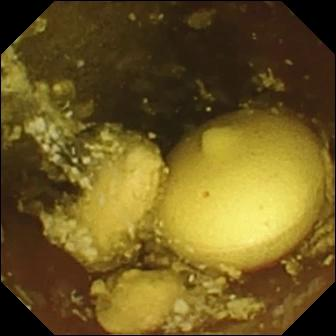


Variant: crop | Roles: ['crop']


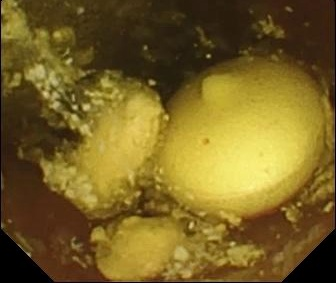


Variant: overlay | Roles: ['overlay']


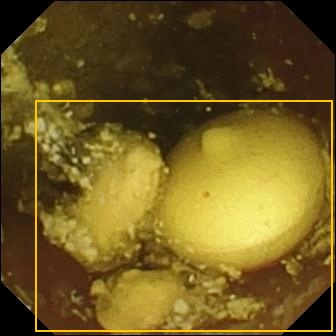


Variant: fullcrop | Roles: ['full_frame', 'region_of_interest']


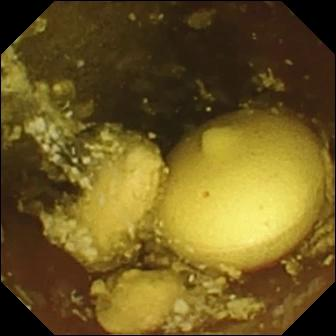

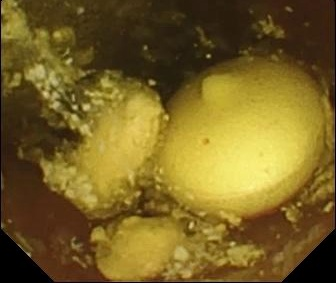


Variant: temporal_multi | Roles: ['temporal_context; frame=8052; offset_seconds=-2', 'temporal_context; frame=8082; offset_seconds=-1', 'target; frame=8112; offset_seconds=+0', 'temporal_context; frame=8142; offset_seconds=+1', 'temporal_context; frame=8172; offset_seconds=+2']


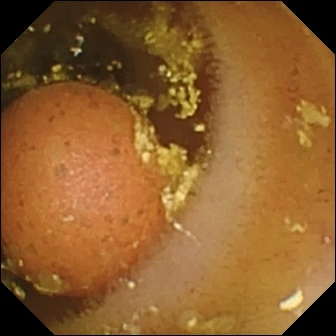

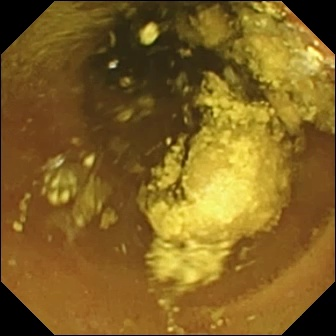

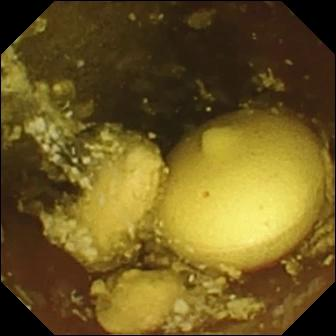

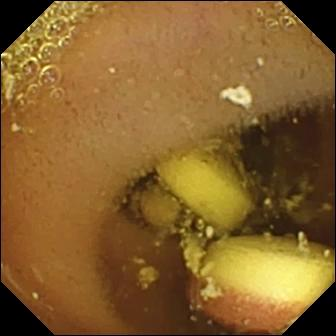

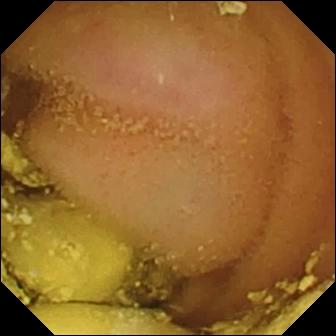


Variant: temporal_collage | Roles: ['temporal_collage']


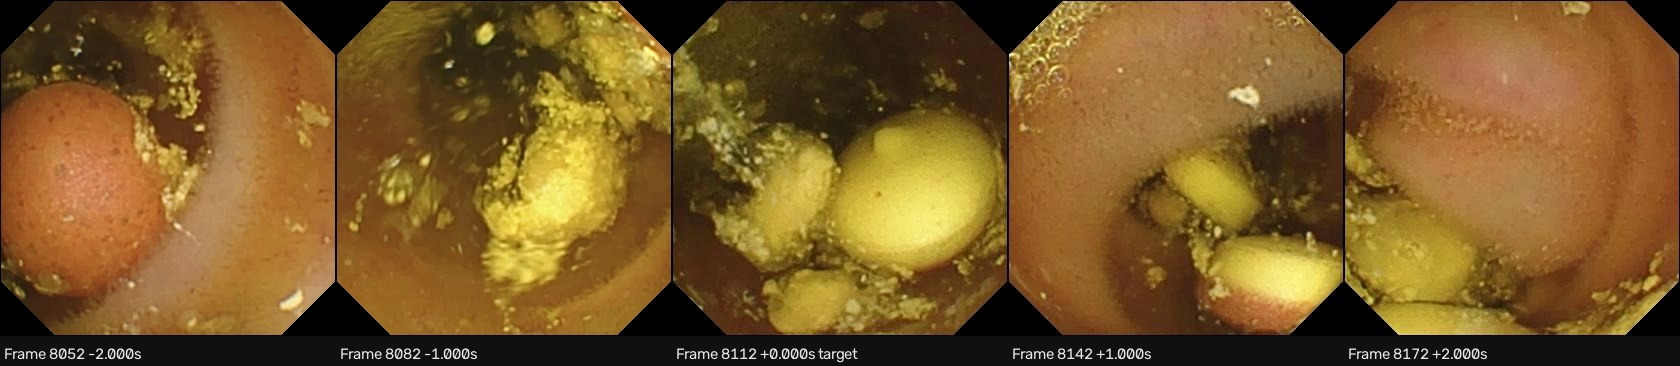

Model fields: ['question', 'images', 'image_roles', 'context']
Reference answer: None
QA validation: not_authored


In [12]:
if CONFIG["load_images"]:
    assert RUN_REPORT["status"] == "image_smoke_passed", "Image checks have not completed successfully."
    for preview in previews:
        print("\nVariant:", preview["provenance"]["variant"], "| Roles:", preview["model"]["image_roles"])
        for image in preview["model"]["images"]:
            display(image)
    MODEL_INPUT = previews[0]["model"]
    EVALUATOR_INPUT = previews[0]["evaluator"]
    PROVENANCE = previews[0]["provenance"]
    print("Model fields:", list(MODEL_INPUT))
    print("Reference answer:", EVALUATOR_INPUT["reference_answer"])
    print("QA validation:", EVALUATOR_INPUT["qa_validation_status"])
else:
    print("Only metadata were inspected. No model image payload was created.")


## 12. Save the reproducibility reports

The default saves **new report files only** under `MMVQA_Clinical/outputs/phase3/bootstrap_reports/<run-id>_<commit>/`. Source images and S8 metadata are unchanged. Set `save_reports_to_drive=False` to keep reports only in `/content`.

Files: `source_snapshot.json`, `sample_report.json`, `configuration.json`, `evaluator_records.json`, and `provenance.json`. Credentials are not included. `metadata_verified_images_not_checked` is different from `image_smoke_passed`; neither claims a validated QA benchmark.

To reproduce a run, set `CONFIG["ref"]` to its saved `resolved_commit`. Retain this notebook with the reports as the implementation version used.

In [13]:
assert RUN_REPORT["status"] in {"image_smoke_passed", "metadata_verified_images_not_checked"}, "Run has not passed."
RUN_REPORT["finished_at"] = datetime.now(timezone.utc).isoformat()
save_reports(REPORT_DIR)
if CONFIG["save_reports_to_drive"]:
    if not STORAGE_ROOT.is_dir():
        raise FileNotFoundError("Mount storage before saving reports to Drive.")
    saved_dir = STORAGE_ROOT / "outputs/phase3/bootstrap_reports" / (RUN_ID + "_" + RESOLVED_COMMIT[:12])
    save_reports(saved_dir)
    print("Reports saved:", saved_dir)
else:
    print("Reports saved locally:", REPORT_DIR)
print("Final status:", RUN_REPORT["status"])
print("Data commit:", RESOLVED_COMMIT)
print("training_ready = False: authored/validated QA and final group-safe splits are separate next steps.")


Reports saved: /content/drive/MyDrive/MMVQA_Clinical/outputs/phase3/bootstrap_reports/20261104T183559_825320Z_8b91a1b92b01
Final status: image_smoke_passed
Data commit: 8b91a1b92b01870242a09a8f98c1fc4f7f5e6abe
training_ready = False: authored/validated QA and final group-safe splits are separate next steps.


In [19]:
_PHASE3_DESTINATIONS = {
    "configuration.json": "outputs/phase3/sector1/configs/configuration.json",
    "source_snapshot.json": "outputs/phase3/sector1/configs/source_snapshot.json",
    "sample_report.json": "outputs/phase3/sector1/reports/sample_report.json",
    "evaluator_records.json": "outputs/phase3/sector1/results/evaluator_records.json",
    "provenance.json": "outputs/phase3/sector1/results/provenance.json",
}


def phase3_publication_token():
    token = globals().get("GITHUB_TOKEN") or os.environ.get("GITHUB_TOKEN")
    if not token and _publication_userdata is not None:
        try:
            token = _publication_userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    return token


def phase3_github_api(repository, token):
    def request(method, path, payload=None):
        headers = {"Accept": "application/vnd.github+json", "User-Agent": "MMVQA-Phase3-Publisher",
                   "X-GitHub-Api-Version": "2022-11-28"}
        if token:
            headers["Authorization"] = "Bearer " + token
        body = json.dumps(payload, ensure_ascii=False).encode("utf-8") if payload is not None else None
        if body is not None:
            headers["Content-Type"] = "application/json"
        req = Request(f"https://api.github.com/repos/{repository}/{path}", data=body,
                      headers=headers, method=method)
        try:
            with urlopen(req, timeout=120) as response:
                return json.load(response)
        except HTTPError as error:
            raise RuntimeError(f"GitHub {method} {path} failed (HTTP {error.code}). Check token permissions, branch rules and current branch state; no automatic write retry was attempted.") from None
        except URLError:
            raise RuntimeError(f"GitHub {method} {path} did not complete. Inspect the target branch before rerunning; no automatic write retry was attempted.") from None
    return request


def phase3_artifact_snapshot(directory):
    root = Path(directory).expanduser().resolve()
    raw, documents = {}, {}
    for name in _PHASE3_DESTINATIONS:
        path = root / name
        if not path.is_file() or path.is_symlink():
            raise ValueError(f"Required regular artifact is missing: {path}")
        if path.stat().st_size > 20 * 1024 * 1024:
            raise ValueError(f"Unexpectedly large artifact: {name}")
        raw[name] = path.read_bytes()  # These immutable byte snapshots are the bytes published.
        documents[name] = json.loads(raw[name].decode("utf-8"))
    config, snapshot, report = (documents[n] for n in ("configuration.json", "source_snapshot.json", "sample_report.json"))
    evaluators, provenance = documents["evaluator_records.json"], documents["provenance.json"]
    if not all(isinstance(value, dict) for value in (config, snapshot, report)):
        raise ValueError("Configuration, source snapshot and report must be JSON objects")
    commit = snapshot.get("resolved_commit")
    if not isinstance(commit, str) or not re.fullmatch(r"[0-9a-f]{40}", commit) or report.get("resolved_commit") != commit:
        raise ValueError("Report and source snapshot do not identify the same resolved source commit")
    if config.get("repository") != snapshot.get("repository") or config.get("ref") != snapshot.get("requested_ref"):
        raise ValueError("Configuration does not match the source snapshot")
    if report.get("status") != "image_smoke_passed" or report.get("training_ready") is not False:
        raise ValueError("Publish a completed image_smoke_passed run; training_ready must remain false")
    samples = report.get("samples")
    if not isinstance(samples, list) or not samples or not isinstance(evaluators, list) or not isinstance(provenance, list):
        raise ValueError("Samples, evaluator records and provenance must be nonempty lists")
    if len(samples) != len(evaluators) or len(samples) != len(provenance):
        raise ValueError("Sample/evaluator/provenance counts differ")
    if not report.get("run_id") or not report.get("finished_at"):
        raise ValueError("Run the successful final save cell before publication")
    variants = config.get("variants")
    count = config.get("per_variant")
    if not isinstance(variants, list) or type(count) is not int or count < 1 or len(samples) != len(variants) * count:
        raise ValueError("Sample count does not match configured variants/per_variant")
    if any(sum(s.get("variant") == variant for s in samples) != count for variant in variants):
        raise ValueError("Sample variants do not match the configuration")
    identities = {r["relative_path"]: (r["sha256"], r["bytes"]) for r in snapshot.get("consumed_artifacts", [])}
    if not identities:
        raise ValueError("Source snapshot has no consumed metadata identities")
    seen = set()
    for sample, evaluator, proof in zip(samples, evaluators, provenance):
        eid = sample.get("example_id")
        if not eid or eid in seen or sample.get("pixels_verified_now") is not True:
            raise ValueError("Every sample must have a unique ID and verified pixels")
        seen.add(eid)
        if proof.get("example_id") != eid or proof.get("subject_id") != sample.get("subject_id") or proof.get("variant") != sample.get("variant"):
            raise ValueError("Sample and provenance identities/order differ")
        evidence = evaluator.get("source_annotation_evidence", {})
        if (evaluator.get("reference_answer") is not None or evaluator.get("qa_validation_status") != "not_authored"
                or evidence.get("subject_id") != proof.get("subject_id")
                or evidence.get("ground_truth_ref") != proof.get("ground_truth_ref")):
            raise ValueError("Evaluator evidence is inconsistent with the preview contract")
        embedded = proof.get("source_snapshot", {})
        if embedded.get("resolved_commit") != commit or embedded.get("repository") != snapshot.get("repository"):
            raise ValueError("Provenance belongs to a different source snapshot")
        if (embedded.get("storage_index") != snapshot.get("storage_index")
                or embedded.get("source_catalog_sha256") != snapshot.get("source_catalog_sha256")):
            raise ValueError("Provenance identifies different source metadata")
        for record in embedded.get("consumed_artifacts", []):
            if identities.get(record["relative_path"]) != (record["sha256"], record["bytes"]):
                raise ValueError("Provenance consumed metadata differs from the run snapshot")
        inputs = proof.get("inputs", [])
        if len(inputs) != sample.get("image_count") or len(sample.get("image_sizes", [])) != len(inputs):
            raise ValueError("Verified image counts/dimensions are incomplete")
        for order, item in enumerate(inputs):
            planned, loaded = item.get("input", {}), item.get("resolution", {})
            for key in ("artifact_id", "input_order", "storage", "relative_path", "sha256", "width", "height"):
                if key not in loaded or loaded[key] != planned.get(key):
                    raise ValueError("Image resolution does not match its input recipe")
            if loaded["input_order"] != order or sample["image_sizes"][order] != [loaded["width"], loaded["height"]]:
                raise ValueError("Image resolution order/dimensions differ from the sample report")
    return raw, report, snapshot


def publish_phase3_artifacts(config, *, api=None, token=None):
    mode, repository, branch = config.get("mode"), config.get("repository"), config.get("branch")
    if mode not in {"preview", "publish"}:
        raise ValueError("mode must be preview or publish")
    if not isinstance(repository, str) or not re.fullmatch(r"[A-Za-z0-9_.-]+/[A-Za-z0-9_.-]+", repository):
        raise ValueError("repository must be owner/name")
    if not isinstance(branch, str) or not branch or any(ord(c) < 32 for c in branch):
        raise ValueError("Provide a valid target branch")
    root = Path(config["source_dir"]).expanduser()
    if not root.is_dir() and config.get("mount_drive_if_needed") and _publication_drive is not None:
        _publication_drive.mount("/content/drive")
    raw, report, snapshot = phase3_artifact_snapshot(root)
    if api is None:
        token = token or phase3_publication_token()
        if mode == "publish" and not token:
            raise ValueError("Publishing requires a GITHUB_TOKEN with permission to write repository contents")
        api = phase3_github_api(repository, token)
    ref_path = "git/ref/heads/" + quote(branch, safe="/")
    base = api("GET", ref_path)["object"]["sha"]
    base_tree = api("GET", "git/commits/" + base)["tree"]["sha"]
    remote_tree = api("GET", "git/trees/" + base_tree + "?recursive=1")
    if remote_tree.get("truncated"):
        raise RuntimeError("Repository tree response was truncated; publication stopped")
    remote = {r["path"]: r for r in remote_tree["tree"]}
    plan = []
    for name, target in _PHASE3_DESTINATIONS.items():
        data = raw[name]
        blob_sha = hashlib.sha1(b"blob " + str(len(data)).encode() + b"\0" + data).hexdigest()
        previous = remote.get(target)
        if previous is not None and previous.get("type") != "blob":
            raise ValueError(f"Target is not a regular file: {target}")
        state = "new" if previous is None else "unchanged" if previous["sha"] == blob_sha else "updated"
        plan.append({"source": name, "path": target, "bytes": len(data), "sha256": hashlib.sha256(data).hexdigest(), "blob_sha": blob_sha, "state": state})
    print("Source directory:", root)
    print("Run:", report["run_id"], "| Data commit:", snapshot["resolved_commit"])
    print("Target:", repository, branch, "| Current target commit:", base)
    for item in plan:
        print(item["state"], item["path"], f"({item['bytes']} bytes)", "SHA-256:", item["sha256"])
    if mode == "preview":
        print("Preview complete. Edit the mode value in the configuration code to 'publish', then rerun the configuration and publication code to commit these artifacts.")
        return {"status": "preview", "target_head": base, "files": plan}
    changes = [p for p in plan if p["state"] != "unchanged"]
    commit = base
    if changes:
        if api("GET", ref_path)["object"]["sha"] != base:
            raise RuntimeError("Target branch moved. Rerun preview before publishing; nothing committed to the branch")
        tree = api("POST", "git/trees", {"base_tree": base_tree, "tree": [
            {"path": p["path"], "mode": "100644", "type": "blob", "content": raw[p["source"]].decode("utf-8")} for p in changes]})
        created = api("POST", "git/commits", {"message": "Publish Phase 3.01 input verification " + str(report["run_id"]), "tree": tree["sha"], "parents": [base]})
        commit = created["sha"]
        if api("GET", ref_path)["object"]["sha"] != base:
            raise RuntimeError("Target branch moved. A commit object was prepared but not attached; rerun preview. No force update was attempted")
        api("PATCH", "git/refs/heads/" + quote(branch, safe="/"), {"sha": commit, "force": False})
    committed_tree = api("GET", "git/commits/" + commit)["tree"]["sha"]
    checked = api("GET", "git/trees/" + committed_tree + "?recursive=1")
    if checked.get("truncated"):
        raise RuntimeError("Publication occurred, but its final tree could not be fully verified")
    committed = {r["path"]: r for r in checked["tree"]}
    for item in plan:
        entry = committed.get(item["path"], {})
        if entry.get("sha") != item["blob_sha"]:
            raise RuntimeError("Publication verification failed for " + item["path"])
        blob = api("GET", "git/blobs/" + entry["sha"])
        if blob.get("encoding") != "base64":
            raise RuntimeError("Unexpected blob encoding while verifying publication")
        data = base64.b64decode(blob["content"])
        if data != raw[item["source"]]:
            raise RuntimeError("Committed bytes differ from the source snapshot: " + item["path"])
    status = "published" if changes else "unchanged_verified"
    url = f"https://github.com/{repository}/commit/{commit}"
    print(status, url)
    return {"status": status, "commit": commit, "url": url, "files": plan}


PHASE3_PUBLICATION = publish_phase3_artifacts(PUBLISH_CONFIG)


Source directory: /content/mmvqa_phase3_start/reports/20261104T183559_825320Z
Run: 20261104T183559_825320Z | Data commit: 8b91a1b92b01870242a09a8f98c1fc4f7f5e6abe
Target: bogdanparvu18/msc-graduate-project main | Current target commit: fa342b750050bb29242bd49b686b1528c5be9f33
new outputs/phase3/sector1/configs/configuration.json (609 bytes) SHA-256: e852bbcb2a91497e895806882152a4a61ace27ffe0613d4d86802afebb2bb454
new outputs/phase3/sector1/configs/source_snapshot.json (5572 bytes) SHA-256: f853a31357fe9f92ed6cb34e110bff8acb5fe2da10ea2ee896d46067dda49765
new outputs/phase3/sector1/reports/sample_report.json (3193 bytes) SHA-256: 26ee7279000eeacbd611d0604330b015b5457ae8b3eb3d732bcb7af953c149ea
new outputs/phase3/sector1/results/evaluator_records.json (13107 bytes) SHA-256: c2fe1a7fa7f7e83d5836cce39d7ae36b905c2a83fb7278d81b507b8af30ae274
new outputs/phase3/sector1/results/provenance.json (72699 bytes) SHA-256: 9fd6a4a92381444ad4973250834e5178f392bf58dd0a48fdef65a94ff955630a
published http